# Hartland Quay (Devon) — Surfe

Surfe (Hillier et al.), a radial-basis-function interpolant, fitted to the same
traces and bedding as the LDI fit in `05b_hartland_quay_ldi` and evaluated on the
same grid (`results/inputs.npz`). Run 05b first (it writes `inputs.npz`). Computation and diagnostics only; the plots are not saved. Results go to
`results/` (`surfe.npz`, `surfe.json`,
`meshes_surfe.npz`). This notebook needs `surfepy` but not `curlew` or `torch`.

**The same data as LDI, nothing more.** The traces are distinct beds whose
stratigraphic order is not given, so, as in 05b, each trace is only an equality:
its points share one value, which is free. The Lajaunie method does exactly this.
An interface constraint's level only says which trace a point belongs to (Surfe
constrains the differences within each trace to zero), so the levels are plain
trace labels 0, 1, 2, …; their values and order do not enter the fit. The scale
and the way-up of the field come from the bedding normals alone.

**Global anisotropy.** `SetGlobalAnisotropy(True)` selects Surfe's anisotropic
cubic kernel. The long axis is the smallest eigenvector of the bedding-normal
tensor, and the other two axes are stretched by the square root of their
eigenvalue ratios. That direction is Surfe's estimate from the bedding, not the
hinge the LDI velocity is built around.

The diagnostics are those used for the other examples: interior extrema of the
field (zeros of Surfe's analytic gradient), the bedding misfit and younging,
and the flatness of each trace: the RMS distance (m) of its points from one level
surface (`hartland_inputs.trace_flatness`). The isosurfaces meshed for the 3-D figure are the same number of traces as the
LDI meshes, spaced evenly in this field from the oldest trace to the youngest.
Equal shares of the cloud pile the sheets into the narrow band where most of the
outcrop sits. Each level is the mean of the Surfe field on the trace nearest
that step. They are meshed here rather than in `05d_hartland_quay_meshes`,
because meshing needs the fitted Surfe model, and that notebook runs in the
curlew kernel.

## Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SURFE_BUILD = Path("../../../../surfe/build").resolve()
if SURFE_BUILD.exists() and str(SURFE_BUILD) not in sys.path:
    sys.path.insert(0, str(SURFE_BUILD))
import surfepy

sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
import hartland_inputs  # the held-out traces
figstyle.apply()

OUT_DIR = Path("./results")
inp = np.load(OUT_DIR / "inputs.npz")
names = [str(n) for n in inp["horizon_names"]]
horizons = [inp[f"horizon_{i}"] for i in range(len(names))]
gp, gv = inp["gp"], inp["gv"]
origin = inp["origin"]
x, y, z = inp["x"], inp["y"], inp["z"]

# One label per trace: it only groups each trace's points (their values are equal and free).
labels = np.arange(len(horizons), dtype=float)
print(f"{len(horizons)} traces, {sum(len(h) for h in horizons)} points, {len(gp)} bedding | "
      f"grid {len(x)} x {len(y)} x {len(z)}")

130 traces, 2724 points, 147 bedding | grid 64 x 91 x 27


## Fit

Every trace is a set of interface constraints sharing its label (equal values); each bedding measurement a
planar constraint with its younging normal, so the scalar increases upward. As
elsewhere: the Lajaunie method (`Surfe_API(2)`), the cubic kernel, a
first-order polynomial, and Surfe's global anisotropy.

In [2]:
# Knobs for this fit
KERNEL = "r3"          # cubic; the anisotropic form is ACubic
POLY_ORDER = 1
GLOBAL_ANISOTROPY = False

model = surfepy.Surfe_API(2)
for h, label in zip(horizons, labels):
    for px, py, pz in h:
        model.AddInterfaceConstraint(px, py, pz, float(label))
for (px, py, pz), (nx, ny, nz) in zip(gp, gv):
    model.AddPlanarConstraintwNormal(px, py, pz, nx, ny, nz)
model.SetRBFKernel(KERNEL)
model.SetPolynomialOrder(POLY_ORDER)
model.SetGlobalAnisotropy(GLOBAL_ANISOTROPY)   # long axis: smallest eigenvector of the bedding-normal tensor
with diagnostics.quiet():   # Surfe prints progress from C++
    model.ComputeInterpolant()

## Evaluate on the saved grid

Scalar and analytic gradient over the volume. Each trace's isovalue is the mean
of the field along it, as curlew sets it for LDI.

In [3]:
phi, gradient = diagnostics.evaluate_surfe(model, x, y, z)
trace_isovalues = diagnostics.surfe_isovalues(model, horizons)
print("isovalues:", trace_isovalues.min().round(2), "to", trace_isovalues.max().round(2))

isovalues: 43.48 to 97.96


## Critical points

In [4]:
critical = diagnostics.surfe_critical_points(model, x, y, z, gradient_grid=gradient)
print("Surfe gradient critical points:", critical.counts)

Surfe gradient critical points: {'maximum': 7, 'minimum': 2, 'saddle': 22, 'degenerate': 0}


## Diagnostics

The angle between the predicted and observed bedding normals (a reversal means
the younging is wrong there) and how well each trace sits on a level surface.

In [5]:
grad_fn = diagnostics.make_surfe_gradient_function(model)
g_bed = grad_fn(gp)
cosang = (g_bed * gv).sum(1) / (np.linalg.norm(g_bed, axis=1) * np.linalg.norm(gv, axis=1))
theta = np.degrees(np.arccos(np.clip(cosang, -1.0, 1.0)))

def value_and_gradient(points):
    return diagnostics.surfe_scalar(model, points), grad_fn(points)


flatness = hartland_inputs.trace_flatness(value_and_gradient, horizons)

print(f"younging angle at {len(gp)} points: median {np.median(theta):.1f} deg, mean {theta.mean():.1f} deg, "
      f"fraction reversed {float(np.mean(cosang < 0)):.2f}")
print(f"flatness of the fitted traces (m): median {np.median(flatness):.2f}, max {flatness.max():.2f}")
comparison = {"extrema": critical.counts, "younging_deg_median": float(np.median(theta)),
              "younging_deg_mean": float(theta.mean()), "fraction_reversed": float(np.mean(cosang < 0)),
              "flatness_m_median": float(np.median(flatness)), "flatness_m_max": float(flatness.max())}

younging angle at 147 points: median 0.0 deg, mean 0.0 deg, fraction reversed 0.00
flatness of the fitted traces (m): median 0.00, max 0.00


### Held-out contacts and bedding

The test traces are the two pairs 05a held out of the fit and clubbed, H22 with H25
and H0 with H7, the same traces 05b scores. The flatness of each is the RMS distance (m)
of its points from the one level surface that fits them
best, each point's distance taken with its own gradient (`hartland_inputs.trace_flatness`),
as for the fitted traces above and as 05b reports for LDI on the same traces. Rescaling a
field does not change it, so the two fits compare directly. Surfe passes exactly through
the fitted traces (flatness ≈ 0), so these two traces are where the two can be compared. The held-out bedding
is the split 05a made, and its younging is the same angle as for the fitted
readings. It is a check only once this fit was trained on the training split,
which is what 05b writes into `inputs.npz`.

In [6]:
data = hartland_inputs.load_processed()
heldout_names, heldout = hartland_inputs.heldout_traces(data)
heldout_flatness = hartland_inputs.trace_flatness(value_and_gradient, heldout)
print(f"{len(heldout)} held-out traces ({sum(len(t) for t in heldout)} points): flatness median "
      f"{np.median(heldout_flatness):.2f} m, 90th pct {np.percentile(heldout_flatness, 90):.2f}, "
      f"max {heldout_flatness.max():.2f}")
for name, fl in zip(heldout_names, heldout_flatness):
    print(f"  {name}: flatness {fl:.2f} m")
gp_test, gv_test = data["gp_test"], data["gv_test"]
if np.linalg.norm(gp_test[:, None, :] - gp[None, :, :], axis=2).min() < 1e-3:
    print("held-out bedding is among the fitted readings; re-run 05b so the fit uses the training split")
g_test = grad_fn(gp_test)
cos_t = (g_test * gv_test).sum(1) / (np.linalg.norm(g_test, axis=1) * np.linalg.norm(gv_test, axis=1))
theta_test = np.degrees(np.arccos(np.clip(cos_t, -1.0, 1.0)))
print(f"younging angle, held-out bedding ({len(gp_test)}): median {np.median(theta_test):.1f} deg, "
      f"90th pct {np.percentile(theta_test, 90):.1f}, reversed {float(np.mean(cos_t < 0)):.2f}")
comparison.update({"heldout_traces": len(heldout), "heldout_flatness_m_median": float(np.median(heldout_flatness)),
                   "heldout_flatness_m_p90": float(np.percentile(heldout_flatness, 90)),
                   "heldout_flatness_m_max": float(heldout_flatness.max()),
                   "younging_deg_median_test": float(np.median(theta_test)),
                   "younging_deg_p90_test": float(np.percentile(theta_test, 90))})

2 held-out traces (2360 points): flatness median 9.84 m, 90th pct 13.80, max 14.79
  H22+H25: flatness 14.79 m
  H1+H7: flatness 4.90 m
younging angle, held-out bedding (20): median 21.0 deg, 90th pct 35.1, reversed 0.00


## Visual check

Not saved: Surfe's scalar on a *y*–*z* plane through the median trace *x*, with
the traces within 40 m of it, and the contours at the isovalues of the traces.

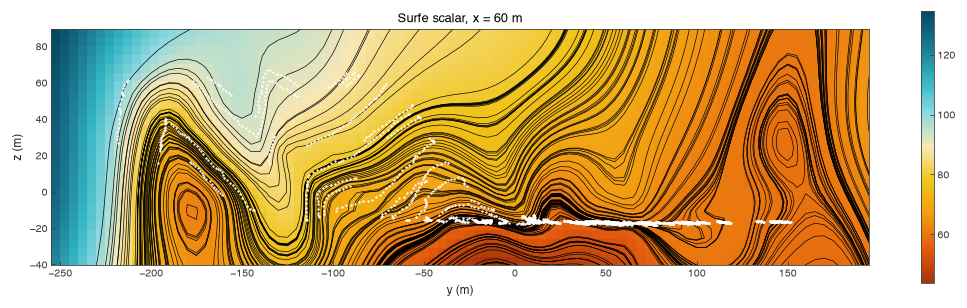

In [7]:
x_slice = float(np.median(np.vstack(horizons)[:, 0]))
i = int(np.argmin(np.abs(x - x_slice)))
fig, ax = plt.subplots(figsize=(11, 4.2))
m = ax.imshow(phi[i].T, origin="lower", extent=(y[0], y[-1], z[0], z[-1]), cmap=figstyle.ramp(), aspect="equal")
ax.contour(y, z, phi[i].T, levels=np.sort(trace_isovalues), colors="k", linewidths=0.4)
for h in horizons:
    near = np.abs(h[:, 0] - x_slice) < 40
    ax.scatter(h[near, 1], h[near, 2], s=2, c="w", linewidths=0, zorder=5)
ax.set(xlabel="y (m)", ylabel="z (m)", title=f"Surfe scalar, x = {x_slice + origin[0]:.0f} m")
fig.colorbar(m, ax=ax, shrink=0.7)
plt.show()

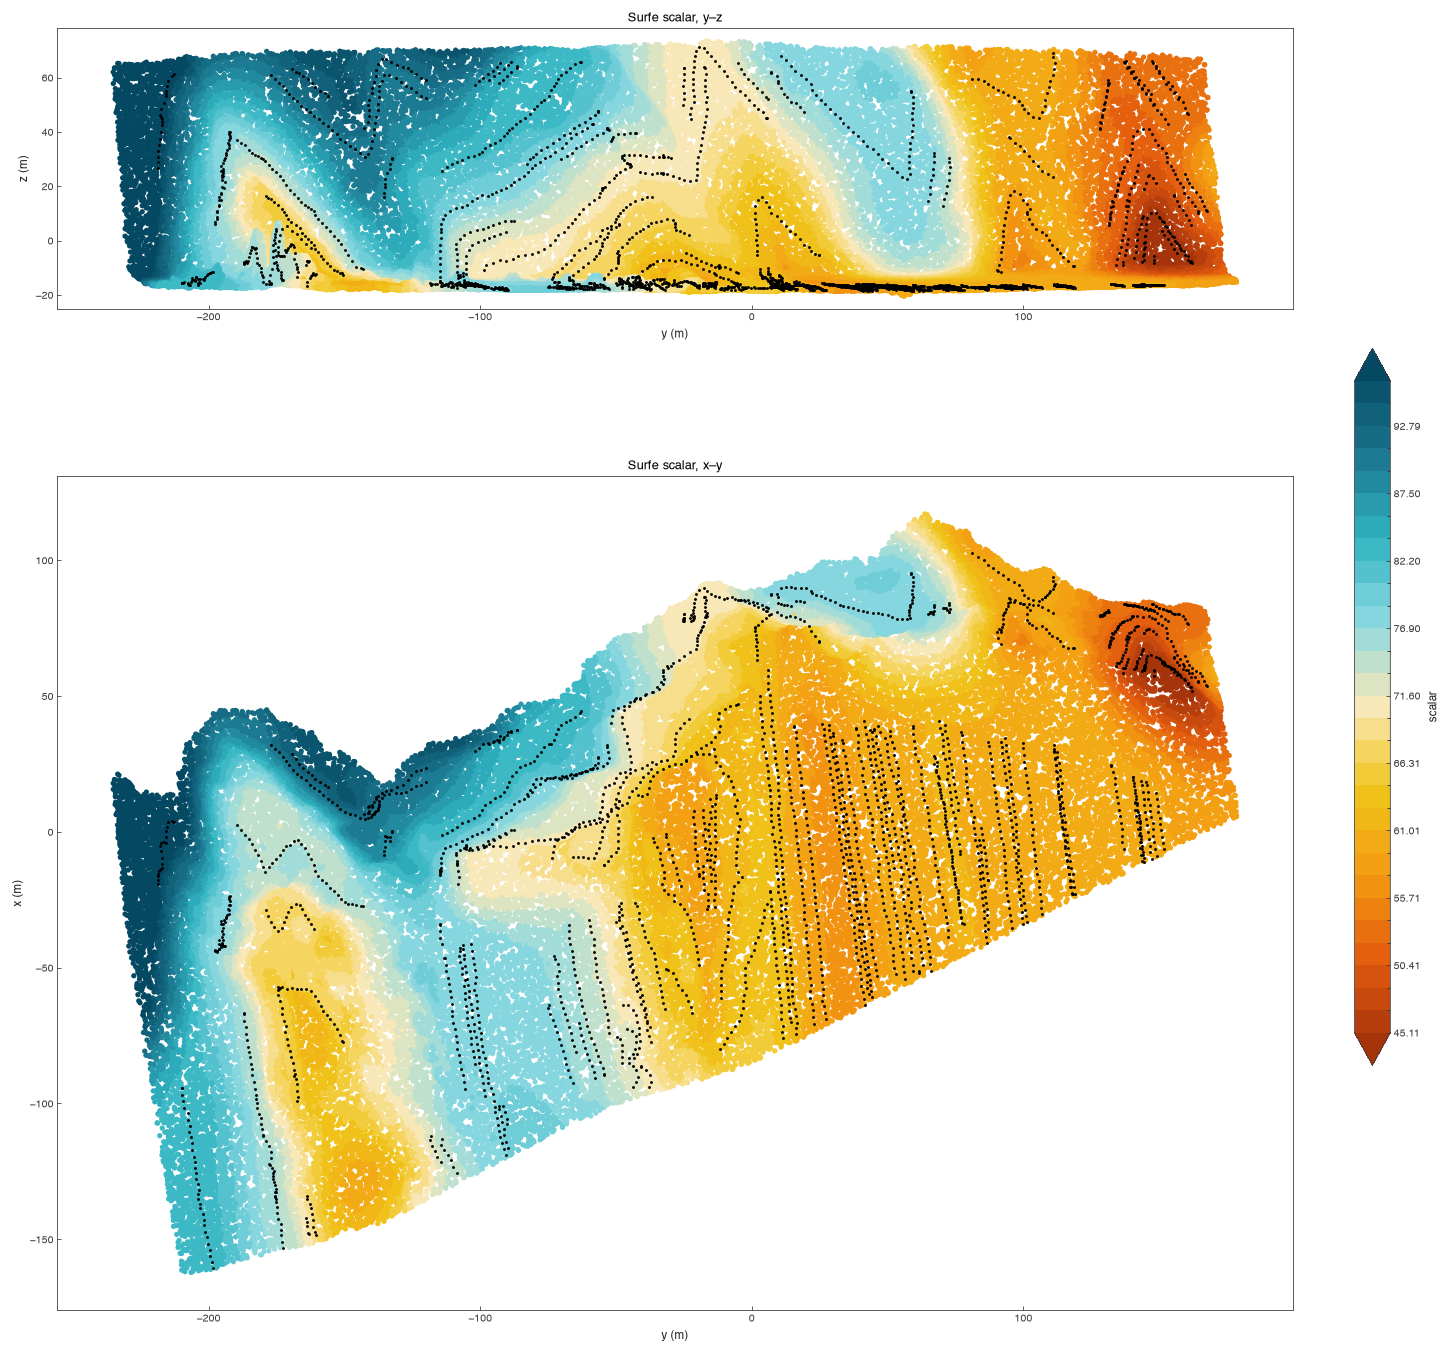

In [8]:
# Not saved: Surfe's scalar on the 05a point cloud, in discrete bands. The band edges are
# N_BANDS evenly spaced levels between the youngest and oldest trace, for the display only.
N_BANDS = 30
cloud_xyz = inp["cloud_xyz"].astype(float)
phi_cloud = diagnostics.surfe_scalar(model, cloud_xyz)
band_edges = diagnostics.evenly_spaced_levels(trace_isovalues, N_BANDS)
diagnostics.plot_cloud_scalar(cloud_xyz, phi_cloud, band_edges, lines=horizons, title="Surfe scalar", size=10.)
plt.show()

## Isosurfaces

The same number of traces as the LDI meshes (`results/beds.npz`). The levels are
spaced evenly from the oldest trace to the youngest, and each sheet is the trace
nearest that level, ordered youngest first. Marching cubes on a regular grid
(scikit-image) over the grid's box.

The small closed level surface just inside each interior extremum is meshed too (finer step), for the figure's purple enclosures.

In [9]:
def _spread(depths, targets):
    """Trace indices paired, in order, to target levels, each trace used once."""
    depths = np.asarray(depths, float)
    targets = np.sort(np.asarray(targets, float))
    order = np.argsort(depths, kind="mergesort")
    d = depths[order]
    m, n = len(targets), len(d)
    if n < m:
        raise ValueError(f"need {m} traces, have {n}")
    cost = np.empty((m, n))
    prev = np.full((m, n), -1, int)
    cost[0] = np.abs(d - targets[0])
    for j in range(1, m):
        best, arg = np.inf, -1
        for i in range(n):
            if i > 0 and cost[j - 1, i - 1] < best:
                best, arg = cost[j - 1, i - 1], i - 1
            cost[j, i] = np.inf if arg < 0 else abs(d[i] - targets[j]) + best
            prev[j, i] = arg
    chosen = np.empty(m, int)
    i = int(np.argmin(cost[-1]))
    for j in range(m - 1, -1, -1):
        chosen[j] = order[i]
        i = int(prev[j, i])
    return chosen


# Same number of sheets as the LDI meshes. Surfe's scalar piles most of the cloud
# into a narrow band, so equal shares of the cloud stack the sheets there. Space
# the levels evenly from the oldest trace to the youngest, and take the trace
# nearest each level.
bed_path = OUT_DIR / "beds.npz"
if not bed_path.is_file():
    raise FileNotFoundError(f"{bed_path} is missing; run the lithology cell in 05b")
n_beds = len(np.load(bed_path)["names"])
targets = np.linspace(trace_isovalues.min(), trace_isovalues.max(), n_beds)
pick = _spread(trace_isovalues, targets)
order = np.argsort(-trace_isovalues[pick], kind="mergesort")   # youngest (highest scalar) first
pick = pick[order]
bed_names = [names[i] for i in pick]
iso_sel = trace_isovalues[pick]
spacing = float(np.median(np.diff(np.sort(iso_sel))))
print("beds, youngest first:", ", ".join(f"{n} {v:.2f}" for n, v in zip(bed_names, iso_sel)),
      f"| median gap {spacing:.2f}")

STEP = 3.0                                     # m, marching-cubes spacing of the surfaces
SHELL_STEP = 1.0                               # m, and of the small shells round extrema
SHELL_DELTA = 0.08                             # shell level, as a fraction of the median gap between the beds
SHELL_HALF = 15.0                              # m, a shell must close within this distance of its extremum
pad = 10.0
box = np.array([[x[0] - pad, y[0] - pad, z[0] - pad], [x[-1] + pad, y[-1] + pad, z[-1] + pad]])
coarse = diagnostics.surfe_mesher(model, STEP)
fine = diagnostics.surfe_mesher(model, SHELL_STEP)
mesher = lambda level, bounds: (coarse if np.ptp(bounds, axis=0).max() > 100 else fine)(level, bounds)

extrema = [(p, kind, float(diagnostics.surfe_scalar(model, p[None])[0]))
           for kind in ("maximum", "minimum") for p in critical.of_kind(kind)]
mesh_path = OUT_DIR / "meshes_surfe.npz"
diagnostics.export_meshes(mesh_path, mesher, iso_sel, box, extrema=extrema,
                          shell_delta=SHELL_DELTA * spacing, shell_half=SHELL_HALF)
with np.load(mesh_path) as saved:
    arrays = {k: saved[k] for k in saved.files}
arrays["names"] = np.asarray(bed_names)
np.savez_compressed(mesh_path, **arrays)
print(f"wrote meshes_surfe.npz: {len(iso_sel)} surfaces, {len(extrema)} extrema")

beds, youngest first: H0 97.96, H9 93.48, H11 87.84, H40 83.42, H58 78.45, H72 73.04, H16 68.29, H23 62.98, H93 58.40, H32 53.62, H124 48.10, H119 43.48 | median gap 4.78
wrote meshes_surfe.npz: 12 surfaces, 9 extrema


## Save

In [10]:
np.savez_compressed(
    OUT_DIR / "surfe.npz",
    phi=phi.astype(np.float32), trace_isovalues=trace_isovalues,
    kernel=KERNEL, poly_order=POLY_ORDER, global_anisotropy=GLOBAL_ANISOTROPY, iso_levels=iso_sel,
    bed_names=np.asarray(bed_names), younging_angle=theta,
    flatness=flatness, heldout_names=np.asarray(heldout_names), heldout_flatness=heldout_flatness,
    younging_angle_test=theta_test,
    **diagnostics.pack_critical(critical, prefix="critical_"),
)
(OUT_DIR / "surfe.json").write_text(json.dumps(
    {"comparison": comparison, "parameters": {"kernel": KERNEL, "poly_order": POLY_ORDER, "global_anisotropy": GLOBAL_ANISOTROPY, "n_iso": len(iso_sel),
                                              "interfaces": "one free equality per trace (Lajaunie); labels only group points"}}, indent=1))
print("wrote surfe.npz and surfe.json to", OUT_DIR)

wrote surfe.npz and surfe.json to results


In [ ]:
# Spatial block hold-out for Surfe (hartland_inputs.block_folds, the same folds as 05i for LDI). The fitted traces
# are split into 7 blocks of equal count along the fold profile; each of the 5 interior blocks is held out in turn
# (its traces and bedding), and training data within 5 m of it, in u, are dropped, so every held-out trace sits in
# a gap. The end blocks are always fitted: holding them out would test extrapolation, not interpolation.
# Scores: flatness of each held-out trace (m), the angle to the held-out bedding, and interior extrema per fold.
# Written to results/blocks_surfe.npz, which 05i compares with LDI.


def fit_surfe(traces, bed_p, bed_v):
    m = surfepy.Surfe_API(2)
    for k, h in enumerate(traces):
        for px, py, pz in h:
            m.AddInterfaceConstraint(px, py, pz, float(k))
    for (px, py, pz), (nx, ny, nz) in zip(bed_p, bed_v):
        m.AddPlanarConstraintwNormal(px, py, pz, nx, ny, nz)
    m.SetRBFKernel(KERNEL)
    m.SetPolynomialOrder(POLY_ORDER)
    m.SetGlobalAnisotropy(GLOBAL_ANISOTROPY)
    with diagnostics.quiet():
        m.ComputeInterpolant()
    return m


folds = hartland_inputs.block_folds(horizons, gp, data["u_ax"])
CLOUD_EVERY = 4                                    # every 4th cloud point is saved, for the supplement figure (05e)
cloud_sub = inp["cloud_xyz"].astype(float)[::CLOUD_EVERY]
fits, out = [], {}
for f in folds:
    b = f["block"]
    mb = fit_surfe(f["train"], gp[f["bed_train"]], gv[f["bed_train"]])
    gf = diagnostics.make_surfe_gradient_function(mb)
    vg = lambda pts: (diagnostics.surfe_scalar(mb, pts), gf(pts))
    flat = hartland_inputs.trace_flatness(vg, [horizons[k] for k in f["test"]])
    g_t, o_t = gf(gp[f["bed_test"]]), gv[f["bed_test"]]
    c_t = (g_t * o_t).sum(1) / (np.linalg.norm(g_t, axis=1) * np.linalg.norm(o_t, axis=1))
    ang = np.degrees(np.arccos(np.clip(c_t, -1.0, 1.0)))
    crit = diagnostics.surfe_critical_points(mb, x, y, z)
    n_ext = int(crit.counts.get("maximum", 0) + crit.counts.get("minimum", 0))
    fits.append((mb, f["train"], f["test"]))
    ext_pts = np.vstack([np.reshape(crit.of_kind(k), (-1, 3)) for k in ("maximum", "minimum")])
    out.update({f"flat_{b}": flat, f"ang_{b}": ang, f"test_{b}": f["test"], f"extrema_{b}": n_ext,
                f"phi_{b}": diagnostics.surfe_scalar(mb, cloud_sub).astype(np.float32),
                f"levels_{b}": diagnostics.surfe_isovalues(mb, f["train"]), f"ext_xyz_{b}": ext_pts})
    print(f"block {b + 1}: u {f['lo']:6.0f} to {f['hi']:5.0f} m | train {len(f['train'])} traces, {f['bed_train'].sum()} bedding | "
          f"held out {len(f['test'])} traces: flatness median {np.median(flat):.2f} m (90th pct {np.percentile(flat, 90):.2f}), "
          f"{f['bed_test'].sum()} bedding: median {np.median(ang):.1f}°, reversed {int((c_t < 0).sum())} | extrema {n_ext}")
flat_all = np.concatenate([out[f"flat_{f['block']}"] for f in folds])
ang_all = np.concatenate([out[f"ang_{f['block']}"] for f in folds])
print(f"all folds: {len(flat_all)} held-out traces, flatness median {np.median(flat_all):.2f} m "
      f"(90th pct {np.percentile(flat_all, 90):.2f}); {len(ang_all)} held-out bedding, median {np.median(ang_all):.1f}°")
np.savez_compressed(OUT_DIR / "blocks_surfe.npz", blocks=np.array([f["block"] for f in folds]), cloud_every=CLOUD_EVERY, **out)
print("wrote", OUT_DIR / "blocks_surfe.npz")


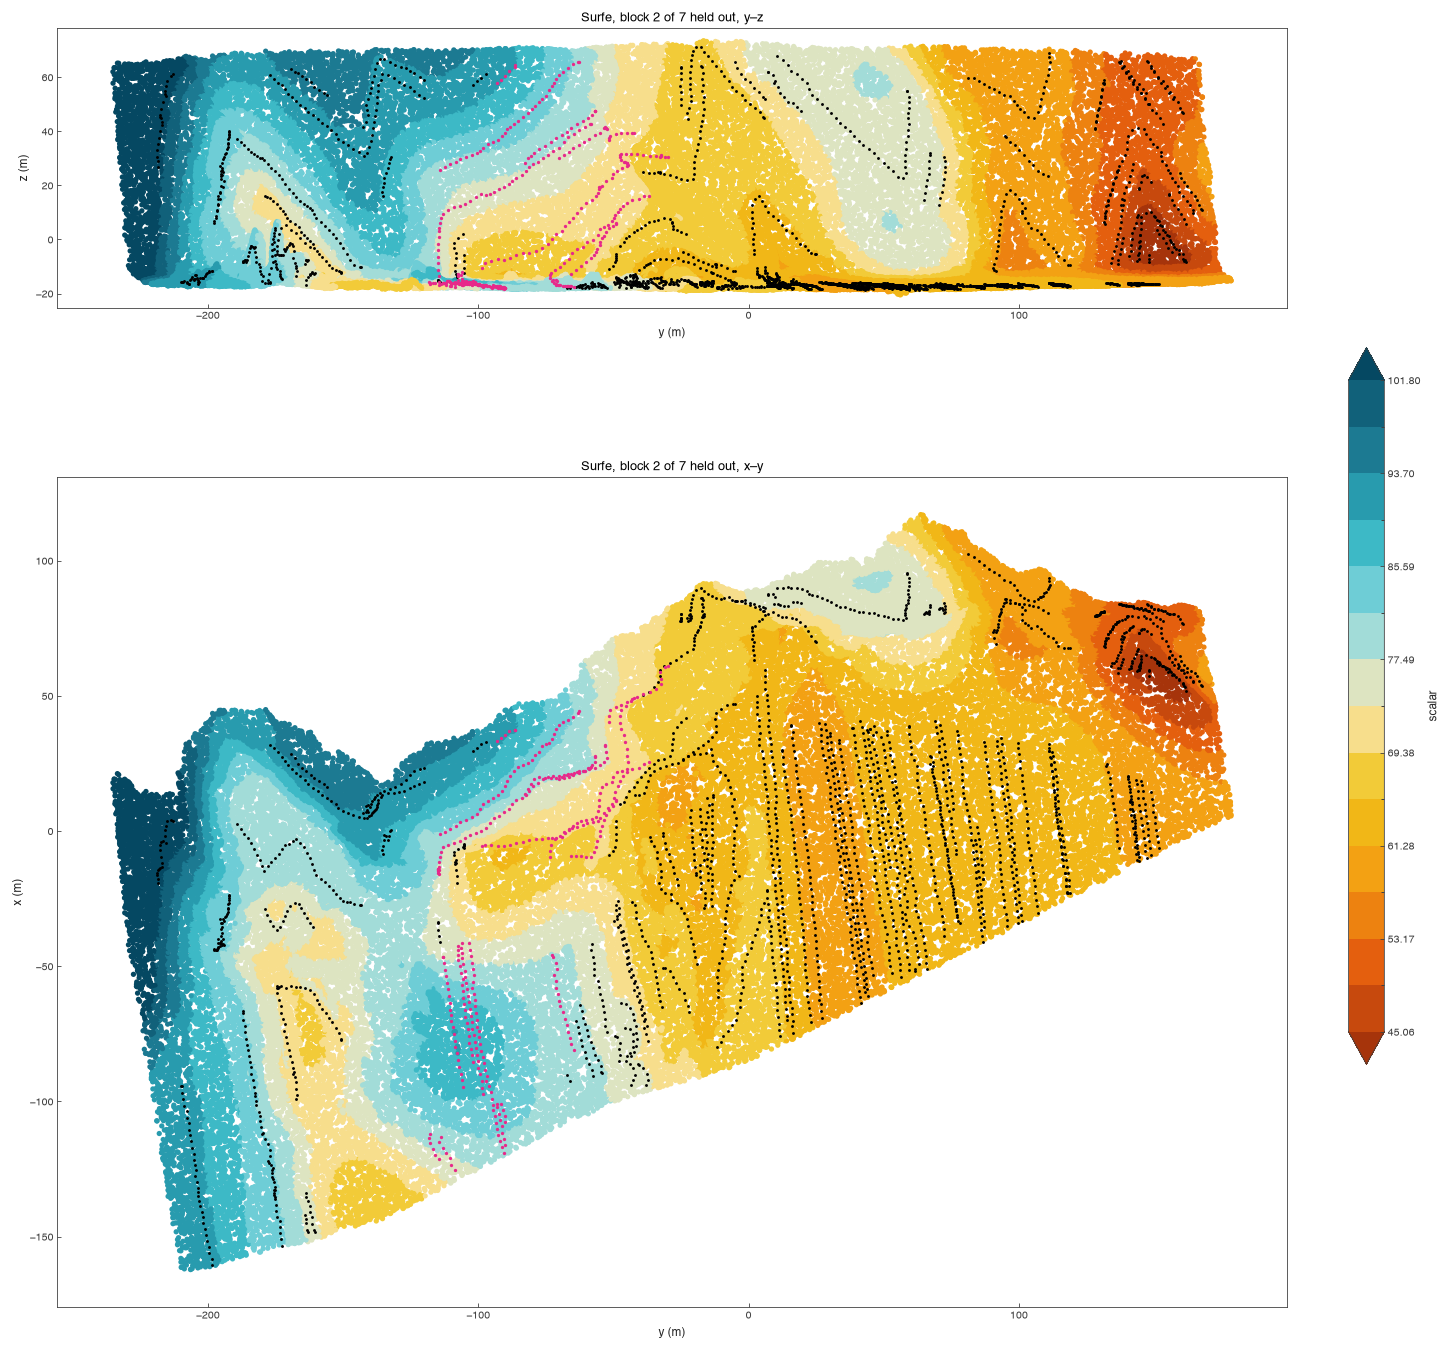

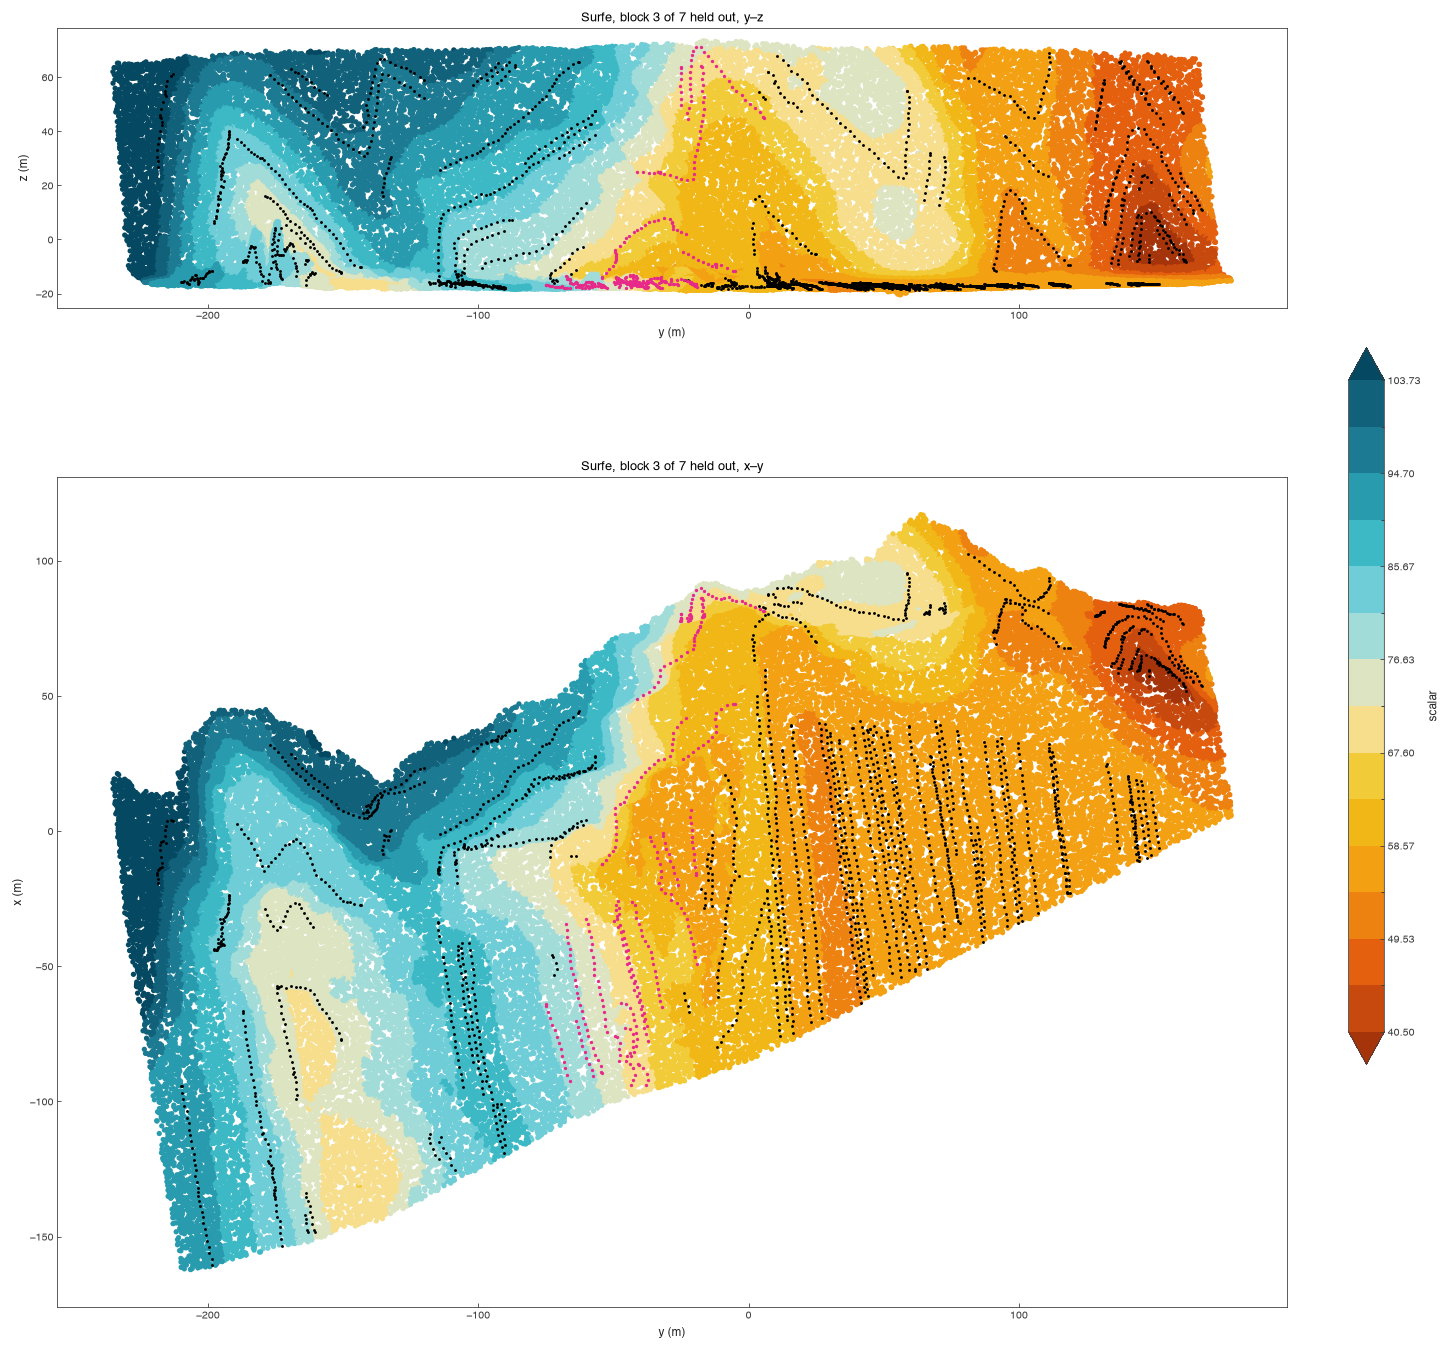

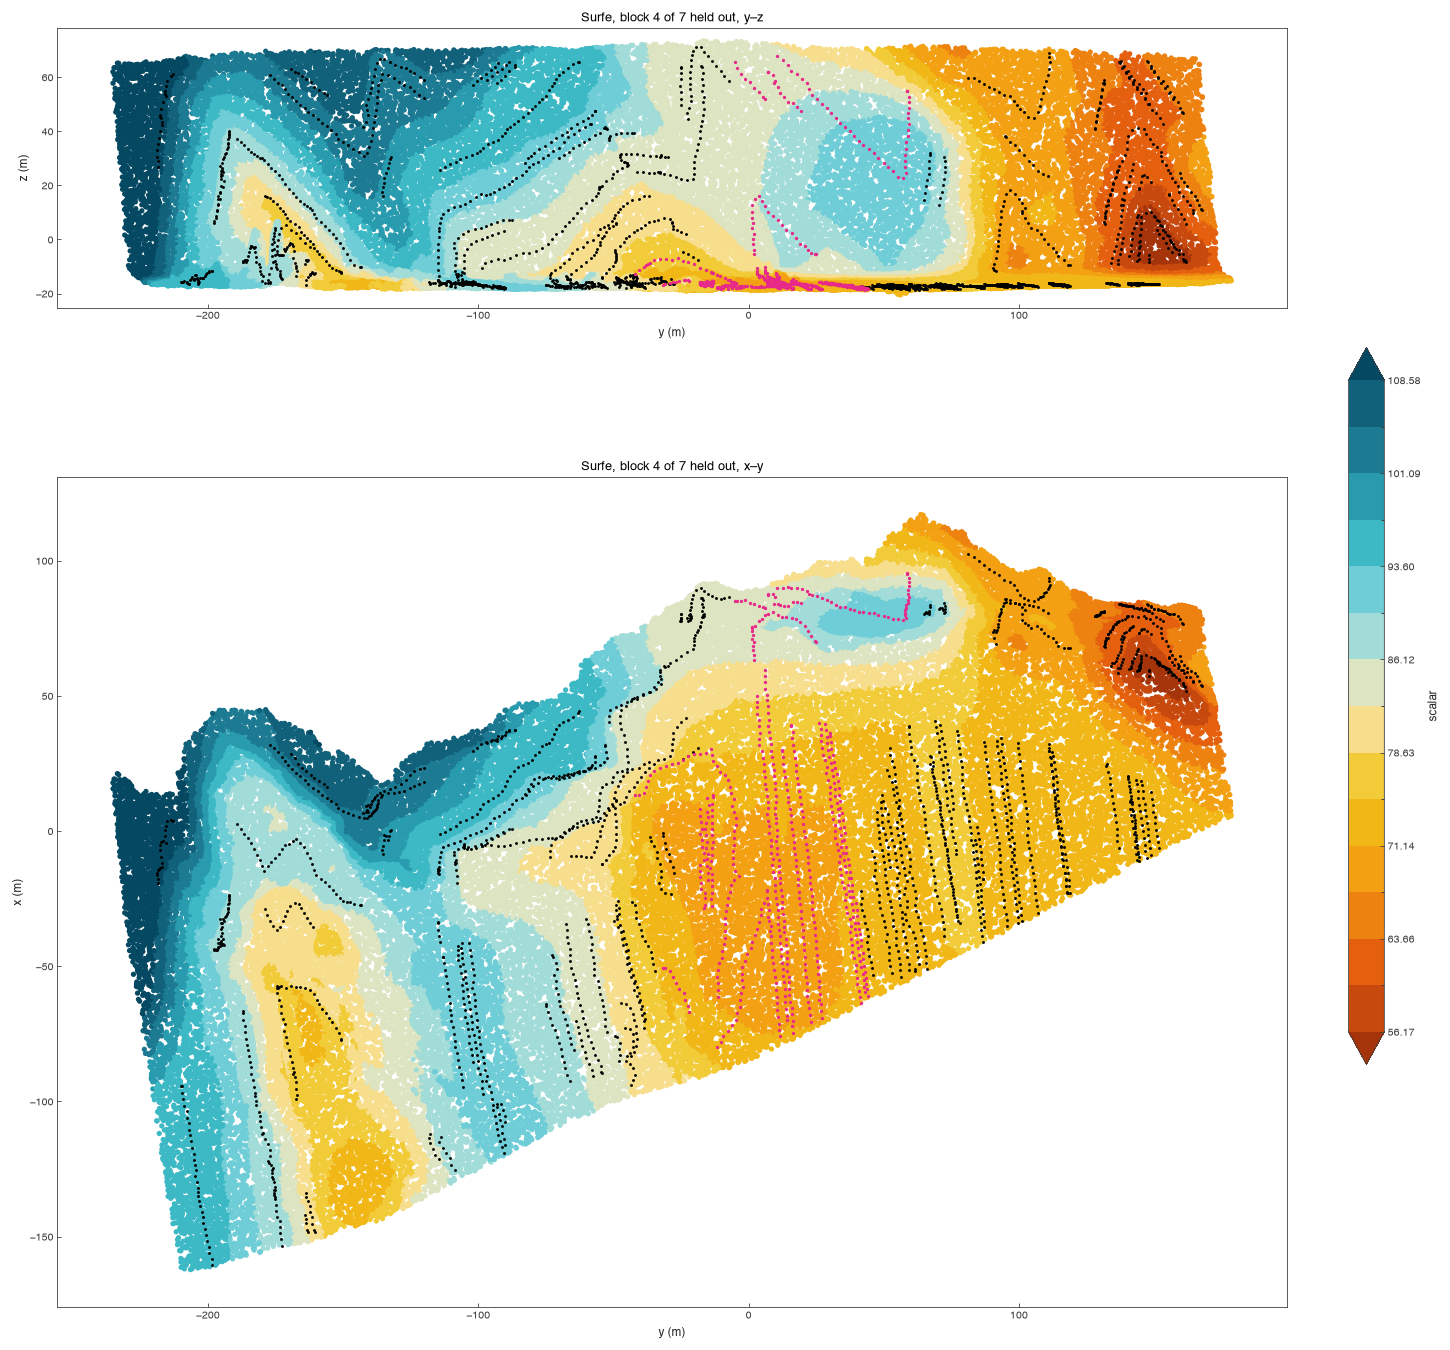

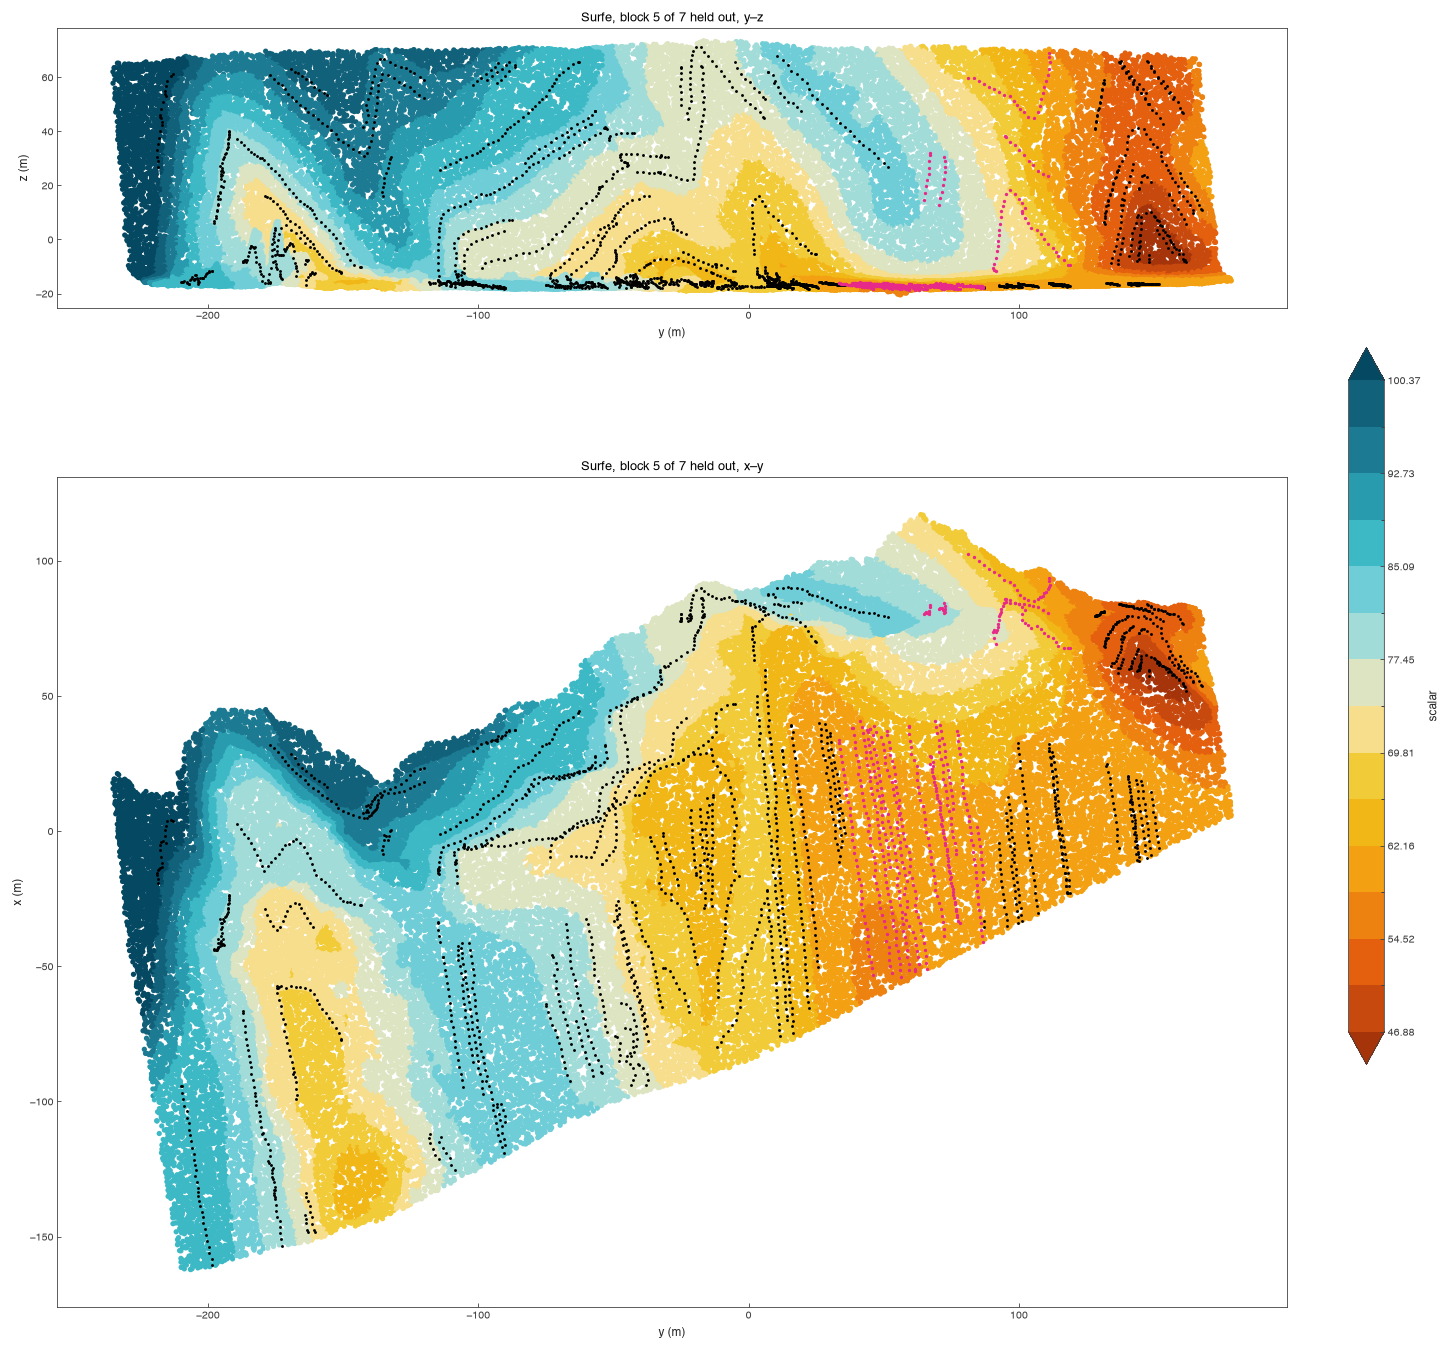

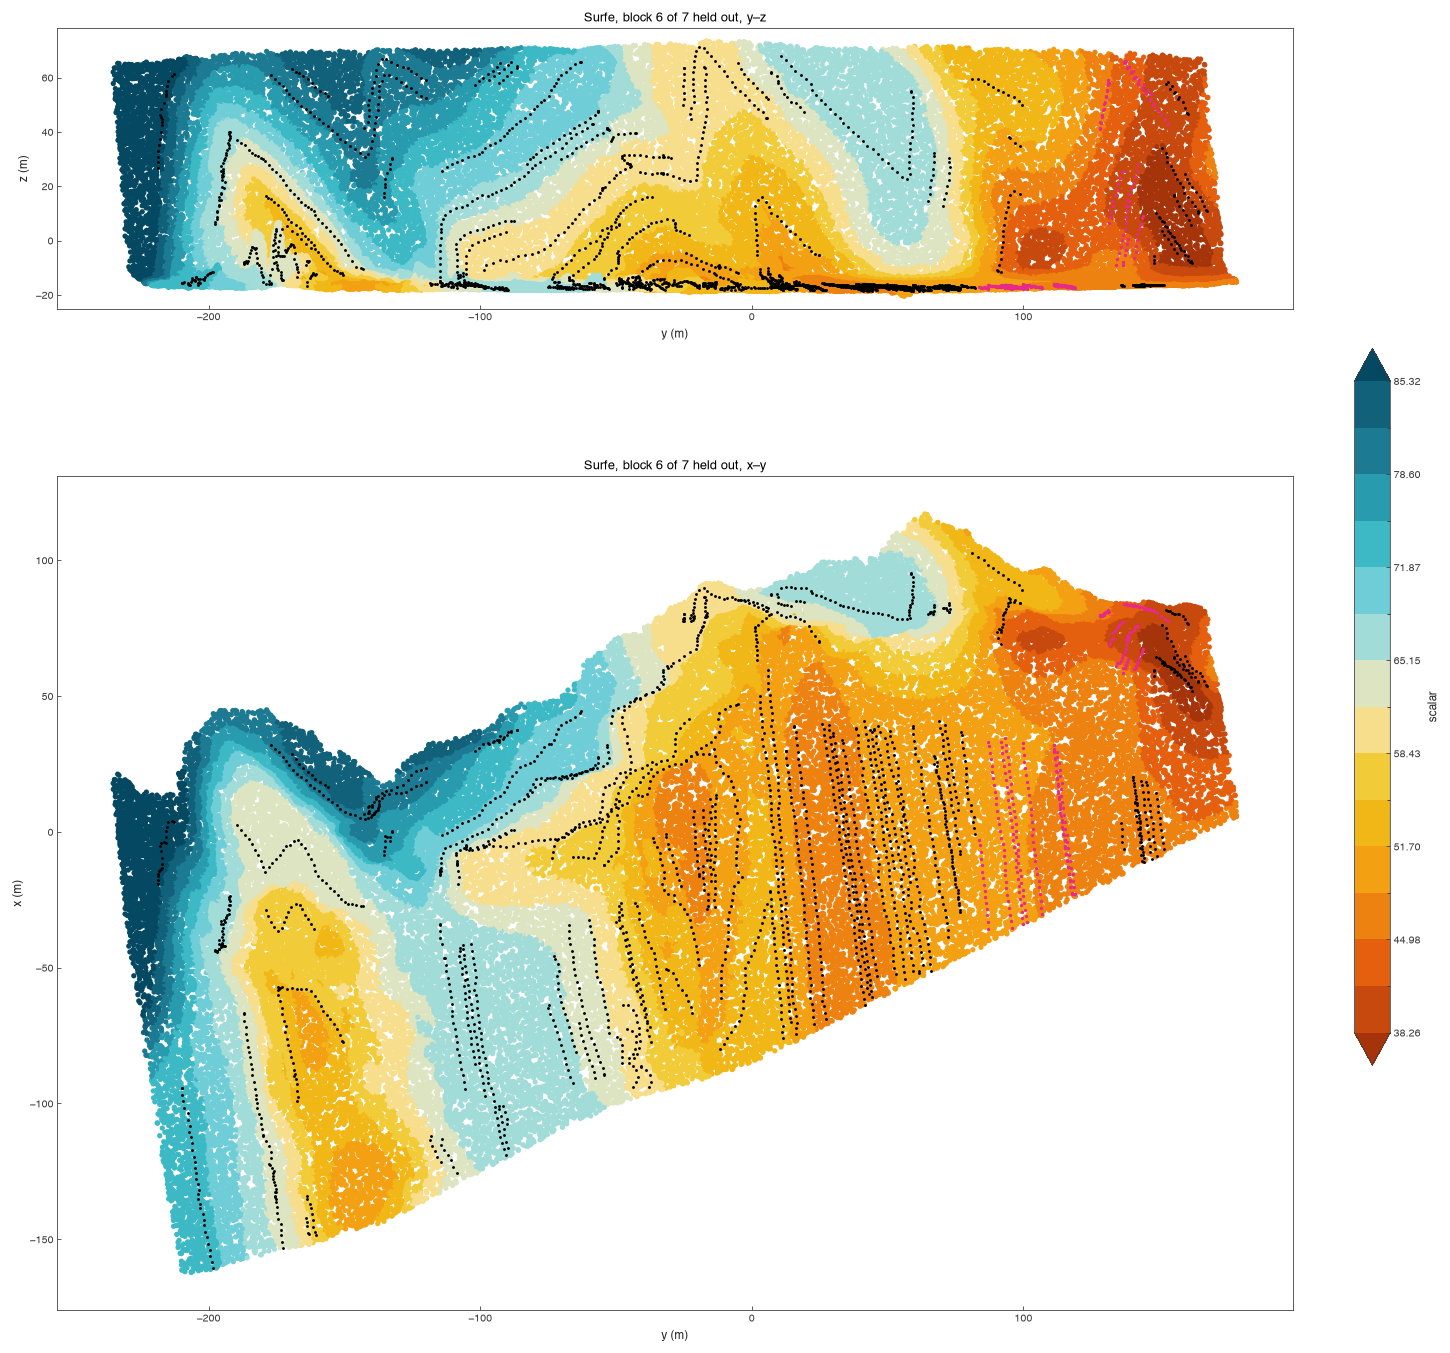

In [12]:
# Quick check (not saved): each block's Surfe fit on the 05a point cloud, in discrete bands. Black: the traces
# that fold was fitted to (after the buffer); magenta: the held-out traces of that block. Band edges are
# N_BANDS evenly spaced levels between the fold's oldest and youngest fitted trace.
N_BANDS = 15
cloud_xyz = inp["cloud_xyz"].astype(float)
for f, (mb, train, test) in zip(folds, fits):
    b = f["block"]
    phi_b = diagnostics.surfe_scalar(mb, cloud_xyz)
    edges_b = diagnostics.evenly_spaced_levels(diagnostics.surfe_isovalues(mb, train), N_BANDS)
    fig, axs = diagnostics.plot_cloud_scalar(cloud_xyz, phi_b, edges_b, lines=train, size=10.,
                                             title=f"Surfe, block {b + 1} of 7 held out")
    for ax, (i, j) in zip(axs, ((1, 2), (1, 0))):
        for k in test:
            ax.scatter(horizons[k][:, i], horizons[k][:, j], s=4, color="#E7298A", linewidths=0, zorder=4)
    plt.show()
